# Three-frequency HILC on a masked sky
Combine **90, 150, 220 GHz** channels with different constant miscalibration angles **0.10°, 0.15°, 0.20°**. All share the same anisotropic rotation field. This is a toy CMB-plus-white-noise experiment with no foregrounds.

Use **nside=512**, **lmax_hilc=lmax_ivf=lmax_qlm=1024**, and field 2 (zero-based) of `binary_GAL_mask_N1024.fits`, averaged down to 512 with fractional boundary weights retained.

Each channel follows: spatial rotation → channel miscalibration → beam smoothing → noise → **mask**. HILC receives these masked maps, not full-sky maps. Its observed-sky weights are also applied to alms of the actual **masked noise**. The cleaned sky is not masked again.

The current isotropic reconstruction filter uses mean HILC noise from a separate calibration ensemble. Rotation plots are raw $C_L$ on log–log axes. No cut-sky response, mode-coupling, or mean-field correction is introduced, so the reconstruction results are diagnostics.

In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sim import CMBobs
from hilc import HILC
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
freqs = np.array([90, 150, 220])  # GHz: channel labels
nlevp = np.array([5., 3., 4.])     # uK-arcmin
fwhm = np.array([20., 15., 10.])  # arcmin
alpha = [0.10, 0.15, 0.20]  # degrees, fixed per channel
assert np.all((np.asarray(alpha) >= 0.1) & (np.asarray(alpha) <= 0.2))
Acb = 1e-6                          # rad²; shared spatial rotation amplitude
nside = 512
lmax_hilc = 1024
hilc_bin_width = 32
lmin_ivf = 20
lmax_ivf = 1024
lmax_qlm = 1024
noise_indices = tuple(range(100, 104))  # filtering calibration ensemble
sim_indices = tuple(range(4))          # reconstruction ensemble
rotation_bin_width = 32
assert not set(noise_indices).intersection(sim_indices)
assert len(sim_indices) >= 2
assert len(freqs) == len(nlevp) == len(fwhm) == 3

mask_path = Path('binary_GAL_mask_N1024.fits')
mask_field = 2
native_mask = hp.read_map(str(mask_path), field=mask_field, dtype=float)
assert hp.npix2nside(len(native_mask)) == 1024
mask = hp.ud_grade(native_mask, nside, order_in='RING', order_out='RING')
del native_mask
mask_hash = hashlib.sha256(mask.tobytes()).hexdigest()

config = dict(mask_sha256=mask_hash, freqs=freqs.tolist(), nlevp=nlevp.tolist(), fwhm=fwhm.tolist(),
              alpha=alpha, Acb=Acb, nside=nside, lmax_hilc=lmax_hilc,
              hilc_bin_width=hilc_bin_width, lmin_ivf=lmin_ivf,
              lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm, noise_indices=noise_indices)
tag = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
root = Path('data') / 'three_frequency_masked_hilc' / tag
obs = CMBobs(nside, nlevp, fwhm, alpha=alpha, Acb=Acb, mask=mask)
hilc = HILC(obs, root / 'hilc', lmax=lmax_hilc, bin_width=hilc_bin_width)
rows = ['| Frequency (GHz) | FWHM (arcmin) | Polarization noise (µK-arcmin) | Miscalibration (deg) |',
        '|---:|---:|---:|---:|']
rows += [f'| {f} | {b:g} | {n:g} | {a:.6f} |' for f, b, n, a in zip(freqs, fwhm, nlevp, alpha)]
display(Markdown('\n'.join(rows)))
print(f'nside={nside}, Acb={Acb:g} rad², cache={root}')
print('Miscalibration angles (degrees):', np.array(alpha))
print(f'Mask mean={mask.mean():.6f}; masked before HILC; no further mask applied.')

| Frequency (GHz) | FWHM (arcmin) | Polarization noise (µK-arcmin) | Miscalibration (deg) |
|---:|---:|---:|---:|
| 90 | 20 | 5 | 0.100000 |
| 150 | 15 | 3 | 0.150000 |
| 220 | 10 | 4 | 0.200000 |

nside=512, Acb=1e-06 rad², cache=data/three_frequency_masked_hilc/5c83faa07402
Miscalibration angles (degrees): [0.1  0.15 0.2 ]
Mask mean=0.700125; masked before HILC; no further mask applied.


## Mask and HILC weights
The mask is already present when HILC transforms the observed maps. T/E/B covariances and weights are therefore fitted to masked-sky alms. Each channel is divided by its nominal polarized beam transfer function. On a cut sky, mask multiplication and beam convolution do **not** commute: this is the existing approximate harmonic treatment, not an exact cut-sky beam inversion.

Weights sum to one per field and multipole bin. Unequal channel calibration angles violate the exact common-polarization assumption; they are retained here. Empirical ILC can also alter the signal through chance correlations.

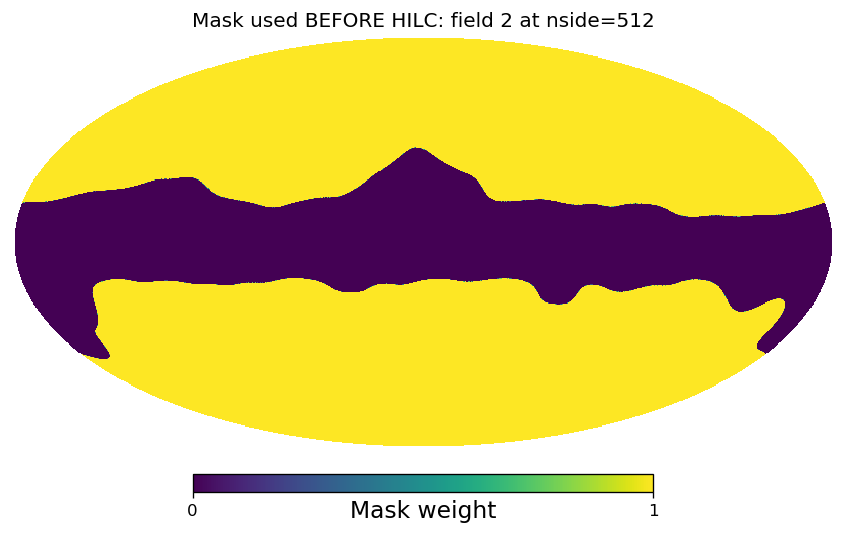

Verified all three observed channels and their noise maps are masked before HILC.


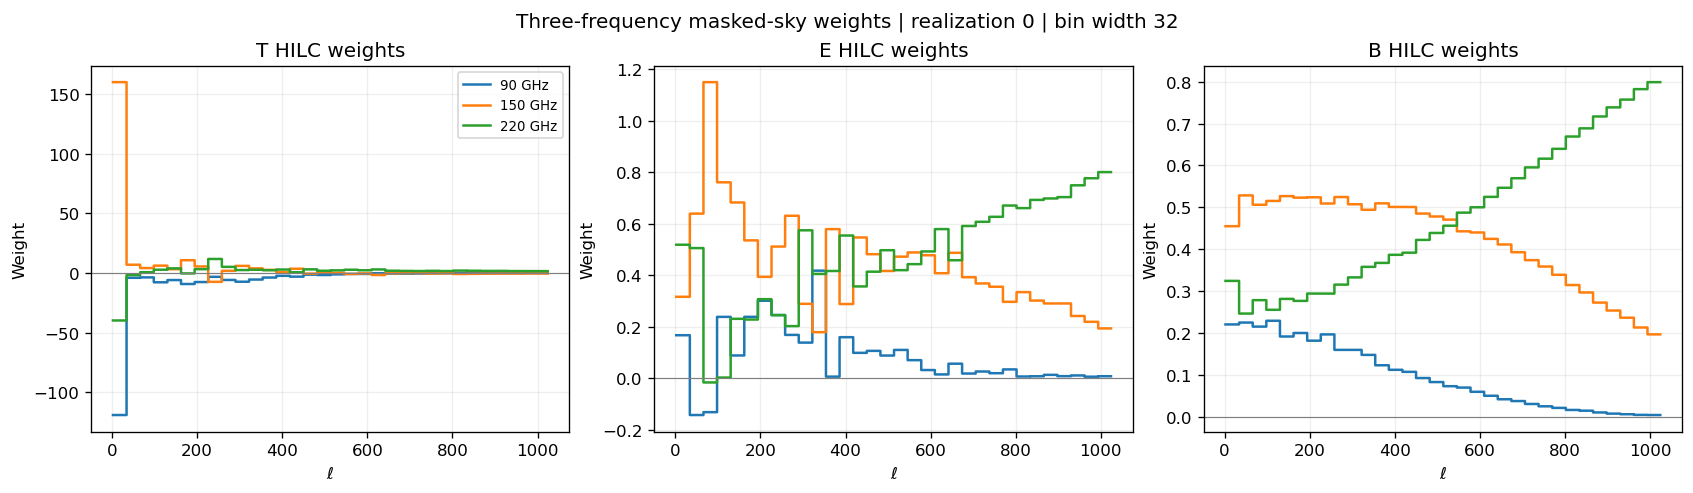

In [2]:
fig = plt.figure(figsize=(8, 4.5))
hp.mollview(mask, fig=fig.number, title='Mask used BEFORE HILC: field 2 at nside=512',
            unit='Mask weight', min=0, max=1, cmap='viridis')
plt.show()

# Check actual HILC input maps, including the masked noise contribution.
check_idx = sim_indices[0]
masked_input = obs.observedmap(check_idx)
masked_noise = obs.noise_map(check_idx)
assert np.all(masked_input[:, :, mask == 0] == 0)
assert np.all(masked_noise[:, :, mask == 0] == 0)
np.testing.assert_array_equal(masked_noise, obs.noise_map(check_idx, apply_mask=False) * mask)
print('Verified all three observed channels and their noise maps are masked before HILC.')
del masked_input, masked_noise

example_idx = sim_indices[0]
clean_example = hilc.cleaned_alms(example_idx)
weights = hilc.weights(example_idx)
ell = np.arange(lmax_hilc + 1)
dl = ell * (ell + 1) / (2 * np.pi)
np.testing.assert_allclose(weights.sum(axis=-1), 1., atol=1e-10)
assert np.isfinite(clean_example).all()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, layout='constrained')
for field, name in enumerate(['T', 'E', 'B']):
    for channel, freq in enumerate(freqs):
        axes[field].step(ell[2:], weights[field, 2:, 0, channel], where='post', label=f'{freq} GHz')
    axes[field].axhline(0, color='gray', lw=0.7)
    axes[field].set(title=f'{name} HILC weights', xlabel=r'$\ell$', ylabel='Weight')
axes[0].legend(fontsize=8)
fig.suptitle(f'Three-frequency masked-sky weights | realization {example_idx} | bin width {hilc_bin_width}')
plt.show()

## Mean masked HILC noise for filtering
Apply each realization's observed-sky weights to its masked-noise alms and average the resulting TT/EE/BB **powers** over calibration indices 100–103. Test indices 0–3 are disjoint.

The colored channel curves and the inverse-noise combination below are **full-sky references only**. The measured HILC noise comes from masked maps and is not expected to attain those references. No sky-fraction rescaling is applied.

Noise calibration 100 complete (19.5 s)


Noise calibration 101 complete (39.4 s)


Noise calibration 102 complete (59.7 s)


Noise calibration 103 complete (81.0 s)


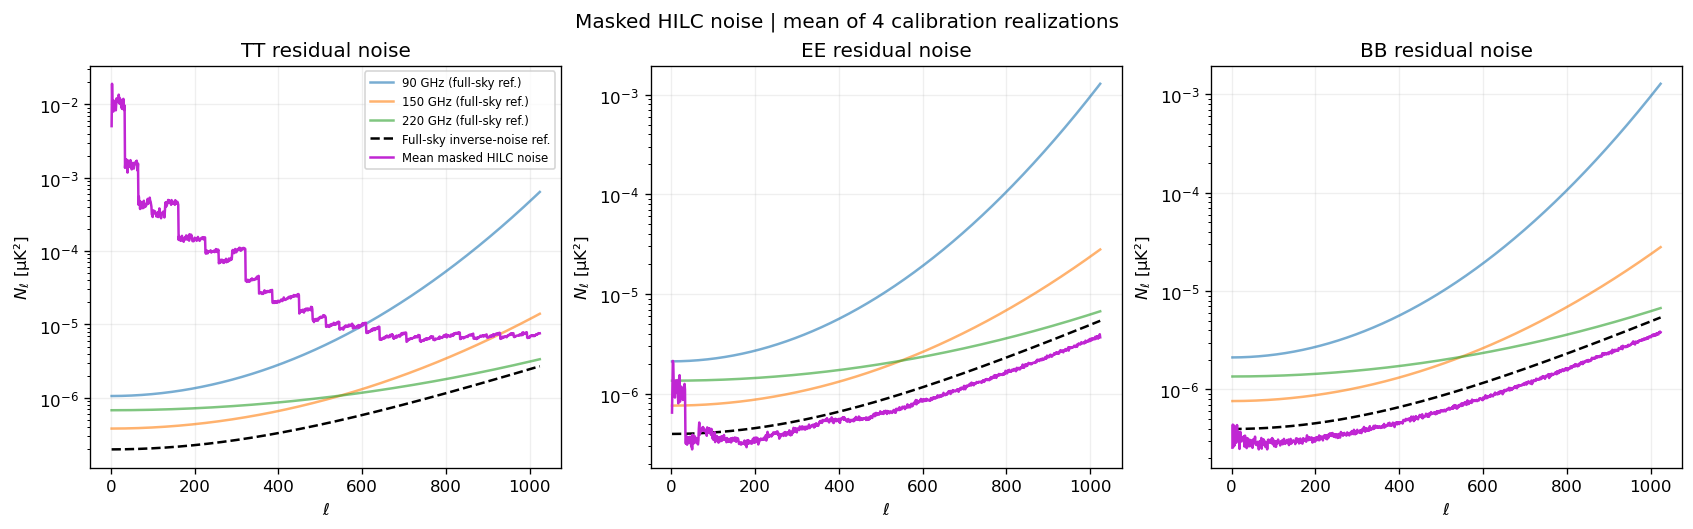

In [3]:
start = time.perf_counter()
noise_samples = []
for idx in noise_indices:
    noise_samples.append(hilc.noise_spectra(idx))
    print(f'Noise calibration {idx} complete ({time.perf_counter()-start:.1f} s)')
mean_noise = np.mean(noise_samples, axis=0)
np.testing.assert_allclose(mean_noise, hilc.mean_noise_spectra(noise_indices))

levels = np.column_stack([obs.nlevt, obs.nlevp, obs.nlevp])
channel_noise = (levels[:, :, None] * np.pi / (180*60) / hilc.beams)**2
ideal_noise = 1 / np.sum(1 / channel_noise, axis=0)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), layout='constrained')
for field, name in enumerate(['TT', 'EE', 'BB']):
    ax = axes[field]
    for channel, freq in enumerate(freqs):
        ax.plot(ell[2:], channel_noise[channel, field, 2:], alpha=0.6, label=f'{freq} GHz (full-sky ref.)')
    ax.plot(ell[2:], ideal_noise[field, 2:], 'k--', label='Full-sky inverse-noise ref.')
    ax.plot(ell[2:], mean_noise[field, 2:], color='#c026d3', lw=1.5, label='Mean masked HILC noise')
    ax.set(title=f'{name} residual noise', xlabel=r'$\ell$',
           ylabel=r'$N_\ell$ [µK²]', yscale='log')
axes[0].legend(fontsize=7)
fig.suptitle(f'Masked HILC noise | mean of {len(noise_indices)} calibration realizations')
plt.show()

## Cleaned masked-sky spectra
All channel and HILC spectra below come from masked observations. The black curve is the actual shared spatially rotated CMB after multiplication by the same mask, before channel miscalibration. The black dashed curve adds the propagated residual noise as a visual reference.

Neither is an exact prediction for HILC: the beams and mask do not commute, channels have different miscalibration, and signal–noise correlations remain. CMB panels retain $D_\ell$ scaling; the rotation plots below use raw $C_L$.

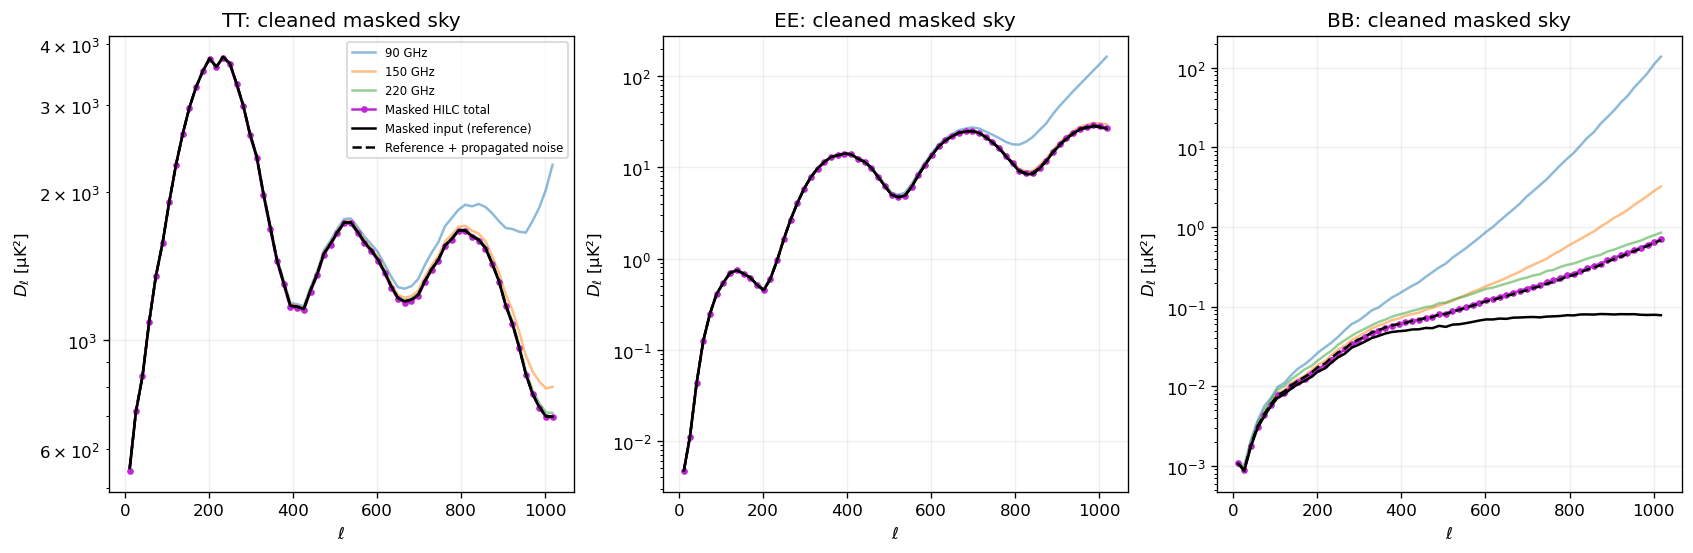

In [4]:
def make_binner(lmax, width, *, dl=False):
    edges = np.append(np.arange(2, lmax+1, width), lmax+1)
    bins = [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:])]
    weights = [(2*b+1)/np.sum(2*b+1) for b in bins]
    centers = np.array([np.sum(b*w) for b, w in zip(bins, weights)])
    factor = (np.arange(lmax+1) * np.arange(1, lmax+2) / (2*np.pi)
              if dl else np.ones(lmax+1))
    def bin_dl(cls):
        return np.stack([np.sum(cls[..., b]*factor[b]*w, axis=-1)
                         for b, w in zip(bins, weights)], axis=-1)
    return centers, bin_dl

cmb_centers, bin_cmb = make_binner(lmax_hilc, 16, dl=True)
raw_maps = obs.observedmap(example_idx)
raw_alms = np.array([hp.map2alm(sky, lmax=lmax_hilc, iter=3) for sky in raw_maps])
for channel in range(len(freqs)):
    for field in range(3):
        hp.almxfl(raw_alms[channel, field], 1/hilc.beams[channel, field], inplace=True)
channel_cls = np.array([[hp.alm2cl(alm) for alm in sky] for sky in raw_alms])
clean_cls = np.array([hp.alm2cl(alm) for alm in clean_example])
truth_teb = hp.map2alm(obs.cmbrotated(example_idx) * mask, lmax=lmax_hilc, iter=3)
truth_cls = np.array([hp.alm2cl(alm) for alm in truth_teb])
noise_example = hilc.noise_spectra(example_idx)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
for field, name in enumerate(['TT', 'EE', 'BB']):
    ax = axes[field]
    for channel, freq in enumerate(freqs):
        ax.plot(cmb_centers, bin_cmb(channel_cls[channel, field]), alpha=0.5, label=f'{freq} GHz')
    ax.plot(cmb_centers, bin_cmb(clean_cls[field]), 'o-', ms=3, color='#c026d3', label='Masked HILC total')
    ax.plot(cmb_centers, bin_cmb(truth_cls[field]), color='black', label='Masked input (reference)')
    ax.plot(cmb_centers, bin_cmb(truth_cls[field]+noise_example[field]), 'k--', label='Reference + propagated noise')
    ax.set(title=f'{name}: cleaned masked sky', xlabel=r'$\ell$', ylabel=r'$D_\ell$ [µK²]', yscale='log')
axes[0].legend(fontsize=7)
plt.show()
del raw_maps, raw_alms

## Rotation reconstruction from masked HILC
`AlphaRecon` uses the measured mean masked HILC noise in `ftl`, `fel`, `fbl`. Cleaned alms are passed directly to the harmonic filter with nominal unit transfer functions; **the mask is not applied a second time**.

The full-sky analytic response and current semi-analytical N0 are unchanged. Reconstructed auto-spectra, input cross-spectra, and N0-subtracted results are **masked-sky diagnostics**, not calibrated cut-sky measurements. The reference is the full-sky injected anisotropic rotation field. The different constant instrumental angles are not removed.

Plots use raw $C_L$ in rad² on log–log axes. Negative bins are shown by open downward triangles at their magnitude and explicitly labeled. Error bars are the standard error over four realizations.

In [5]:
rec = AlphaRecon(hilc, root / 'recon', noise_indices=noise_indices,
                 lmin_ivf=lmin_ivf, lmax_ivf=lmax_ivf, lmax_qlm=lmax_qlm)
for field, key in enumerate(['tt', 'ee', 'bb']):
    np.testing.assert_allclose(rec.noise_cls[key], mean_noise[field, :lmax_ivf+1])
for transfer in rec.transf.values():
    np.testing.assert_array_equal(transfer, 1.)

L = np.arange(lmax_qlm+1)
cl_aa = obs.cl_aa()[:lmax_qlm+1]
# Correct packed-alm truncation: slicing the first nalm elements is wrong.
ls, ms = hp.Alm.getlm(lmax_qlm)
truth_selection = hp.Alm.getidx(obs.lmax, ls, ms)
spectra = {key: [] for key in ['auto', 'cross', 'input', 'n0']}
start = time.perf_counter()
for idx in sim_indices:
    estimate = rec.reconstruct(idx)
    truth = obs.alpha_alm(idx)[truth_selection]
    spectra['auto'].append(hp.alm2cl(estimate))
    spectra['cross'].append(hp.alm2cl(estimate, truth))
    spectra['input'].append(hp.alm2cl(truth))
    spectra['n0'].append(rec.noise_spectrum(idx))
    print(f'Reconstruction {idx} complete ({time.perf_counter()-start:.1f} s)')
spectra = {key: np.asarray(value) for key, value in spectra.items()}
assert all(np.isfinite(value).all() for value in spectra.values())
assert np.all(spectra['n0'] >= 0)
print('Verified finite outputs and the use of mean HILC noise in the filters.')

/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()


Caching sky fractions...


Reconstruction 0 complete (1.2 s)


Reconstruction 1 complete (36.9 s)


Reconstruction 2 complete (69.6 s)


Reconstruction 3 complete (99.6 s)
Verified finite outputs and the use of mean HILC noise in the filters.


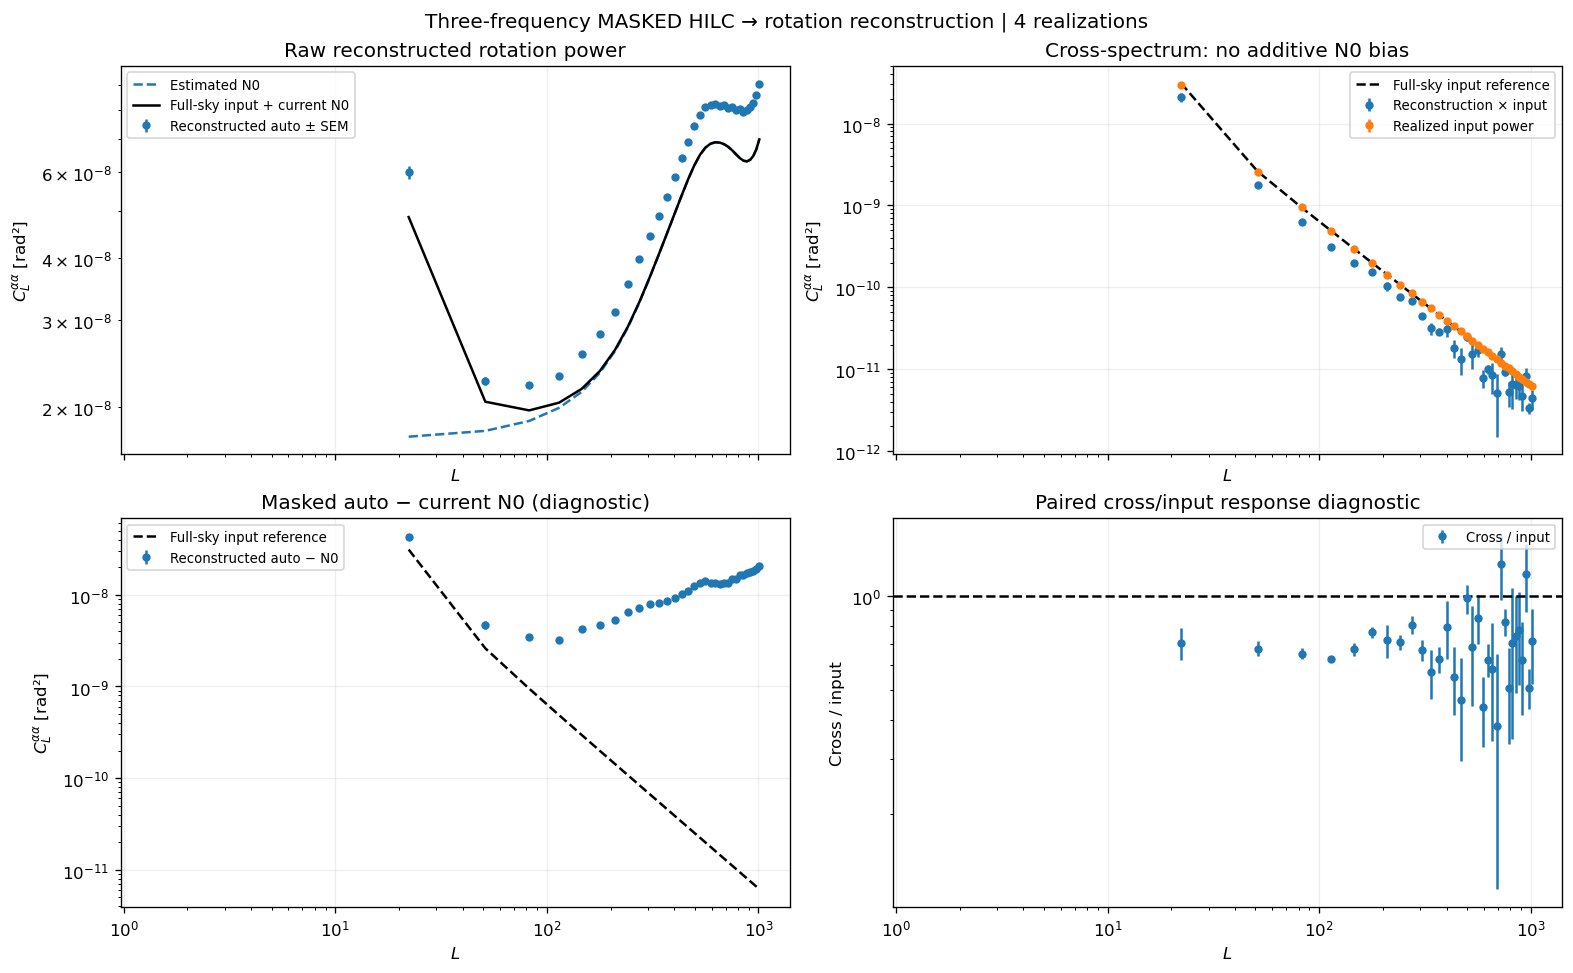

Equal-bin mean cross-minus-input residual: -0.299 ± 0.027 (SEM)
Negative cross bins: 0; negative auto−N0 bins: 0
Saved per-realization raw C_L spectra: data/three_frequency_masked_hilc/5c83faa07402/rotation_spectra.npz


In [6]:
# Rotation spectra use raw C_L, with NO D_L prefactor.
L_b, bin_rotation = make_binner(lmax_qlm, rotation_bin_width, dl=False)
bands = {key: bin_rotation(value) for key, value in spectra.items()}
theory_b = bin_rotation(cl_aa)
np.testing.assert_allclose(bin_rotation(np.ones_like(cl_aa)), 1.)

def mean_sem(samples):
    return samples.mean(axis=0), samples.std(axis=0, ddof=1)/np.sqrt(len(samples))

def log_spectrum(ax, x, y, error, label, color='C0'):
    """Keep negative bandpowers visible on log axes, with an explicit sign marker."""
    positive, negative = y > 0, y < 0
    ax.errorbar(x[positive], y[positive], error[positive], fmt='o', ms=4,
                color=color, label=label)
    if negative.any():
        ax.errorbar(x[negative], -y[negative], error[negative], fmt='v', ms=5,
                    mfc='none', color=color, label=label + ' (negative: magnitude)')
    if np.any(y == 0):
        print(f'{label}: {np.sum(y == 0)} exactly zero bins omitted from log plot')
    ax.set(xscale='log', yscale='log')

auto, auto_err = mean_sem(bands['auto'])
cross, cross_err = mean_sem(bands['cross'])
input_mean, input_err = mean_sem(bands['input'])
n0 = bands['n0'].mean(axis=0)
debiased, debiased_err = mean_sem(bands['auto'] - bands['n0'])
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')
ax = axes[0, 0]
log_spectrum(ax, L_b, auto, auto_err, 'Reconstructed auto ± SEM')
ax.loglog(L_b, n0, '--', label='Estimated N0')
ax.loglog(L_b, theory_b+n0, color='black', label='Full-sky input + current N0')
ax.set_title('Raw reconstructed rotation power')
ax.legend(fontsize=8)
ax = axes[0, 1]
log_spectrum(ax, L_b, cross, cross_err, 'Reconstruction × input')
log_spectrum(ax, L_b, input_mean, input_err, 'Realized input power', color='C1')
ax.loglog(L_b, theory_b, 'k--', label='Full-sky input reference')
ax.set_title('Cross-spectrum: no additive N0 bias')
ax.legend(fontsize=8)
ax = axes[1, 0]
log_spectrum(ax, L_b, debiased, debiased_err, 'Reconstructed auto − N0')
ax.loglog(L_b, theory_b, 'k--', label='Full-sky input reference')
ax.set_title('Masked auto − current N0 (diagnostic)')
ax.legend(fontsize=8)
ax = axes[1, 1]
paired_mean, paired_err = mean_sem(bands['cross'] - bands['input'])
log_spectrum(ax, L_b, 1 + paired_mean/input_mean, paired_err/input_mean, 'Cross / input')
ax.axhline(1, color='black', ls='--')
ax.set(title='Paired cross/input response diagnostic', ylabel='Cross / input')
ax.legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel('$L$')
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.set_ylabel(r'$C_L^{\alpha\alpha}$ [rad²]')
fig.suptitle(f'Three-frequency MASKED HILC → rotation reconstruction | {len(sim_indices)} realizations')
plt.show()

fractional = ((bands['cross']-bands['input'])/theory_b).mean(axis=1)
mean, error = mean_sem(fractional)
print(f'Equal-bin mean cross-minus-input residual: {mean:+.3f} ± {error:.3f} (SEM)')
print(f'Negative cross bins: {np.sum(cross < 0)}; negative auto−N0 bins: {np.sum(debiased < 0)}')
np.savez(root / 'rotation_spectra.npz', ell=L, theory=cl_aa,
         indices=np.asarray(sim_indices), **spectra)
print('Saved per-realization raw C_L spectra:', root / 'rotation_spectra.npz')

## Interpretation
- The mask is applied to each observed frequency and noise realization **before** harmonic cleaning. There is no second mask multiplication on the cleaned alms.
- This is a three-frequency CMB-plus-noise demonstration, with different fixed calibration angles. It does not test foreground removal.
- Mask-induced mode coupling, E/B mixing and mean fields, unequal calibration angles, and data-dependent ILC weights can all affect the reconstruction. The mean cleaned noise spectrum alone does not correct those effects.
- No sky-fraction rescaling, mean-field removal, N1 subtraction, or empirical response correction is applied. The paired input cross-spectrum and N0-subtracted auto-spectrum should be interpreted with these limits.
- Increase the number of independent calibration/test realizations for quantitative validation. Raw per-realization spectra are saved under the printed cache directory.

In the saved run, the equal-bin mean cross-minus-input residual is **−0.299 ± 0.027** (SEM over four realizations). The cross response is therefore around 0.70 with the unchanged normalization, and the N0-subtracted auto-spectrum retains substantial excess power. These outputs are not an unbiased estimate of the input rotation spectrum; no correction was fitted to force agreement.